# Crypto funding rates and perpetual carry

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UnbiasedAlpha/aurastream-python/blob/main/examples/01_crypto_funding_carry.ipynb)

Perpetual futures funding tells you who is paying to hold leverage. When funding is high and positive, longs are crowded, and the cash-and-carry trade (long spot, short perp) earns it.

This notebook pulls **Binance spot prices and USD-M perpetual funding rates** through one AuraStream endpoint, annualizes funding, and compares carry across BTC, ETH and SOL.

**Sources:** `binance` (public, no Binance account needed) · **Calls used:** ~4 of your 500 free monthly calls

In [1]:
%pip install -q "aurastream[pandas]" matplotlib

import os, getpass
if not os.environ.get("AURASTREAM_API_KEY"):
    # Free key, 500 calls/month, no card: https://aurastream.unbiased-alpha.com
    os.environ["AURASTREAM_API_KEY"] = getpass.getpass("AuraStream API key: ")

import pandas as pd
import matplotlib.pyplot as plt
from aurastream_client import AuraStream

client = AuraStream()

## 1. Spot prices

In [2]:
START, END = "2025-01-01", "2025-10-31"
COINS = ["BTCUSDT", "ETHUSDT", "SOLUSDT"]

spot = client.get_panel(COINS, START, END, "1d", source="binance")
spot.tail()

,BTCUSDT,ETHUSDT,SOLUSDT
timestamp,,,
2025-10-28 00:00:00+00:00,114107.65,4120.15,198.70
2025-10-29 00:00:00+00:00,112898.45,3979.20,194.15
2025-10-30 00:00:00+00:00,110021.29,3902.99,193.88
2025-10-31 00:00:00+00:00,108322.88,3805.09,184.69
2025-11-01 00:00:00+00:00,109608.01,3847.99,187.21


## 2. Funding rates

The same endpoint, with `instrument="futures"` and `bars="funding"`. Binance settles funding every 8 hours.

In [3]:
raw = client.timeseries(COINS, START, END, "8h", source="binance", instrument="futures", bars="funding")

from aurastream_client.frames import to_frame
funding_frames = {t: to_frame(raw, t) for t in COINS}
funding_frames["BTCUSDT"].head()

,fundingRate
timestamp,
2025-01-01 00:00:00+00:00,0.0001
2025-01-01 08:00:00+00:00,0.0001
2025-01-01 16:00:00+00:00,0.0001
2025-01-02 00:00:00+00:00,0.0001
2025-01-02 08:00:00+00:00,0.0001


In [4]:
def funding_column(df):
    """Pick the funding-rate column, whatever the source names it."""
    for c in df.columns:
        if "fund" in str(c).lower() and pd.api.types.is_numeric_dtype(df[c]):
            return c
    numeric = df.select_dtypes("number").columns
    if len(numeric) == 1:
        return numeric[0]
    raise KeyError(f"No funding column found in {list(df.columns)}")

funding = pd.DataFrame({t: df[funding_column(df)] for t, df in funding_frames.items()})

# 3 settlements a day x 365 days, in percent
funding_ann = funding * 3 * 365 * 100
funding_daily_ann = funding_ann.resample("1D").mean()
funding_daily_ann.describe().round(2)

,BTCUSDT,ETHUSDT,SOLUSDT
count,304.00,304.00,304.00
mean,5.09,4.98,0.15
std,3.89,4.13,17.03
min,-11.06,-14.07,-242.85
25%,2.53,2.19,-2.76
50%,4.96,5.01,1.86
75%,8.23,8.13,6.92
max,10.95,10.95,16.74


## 3. Funding vs. price

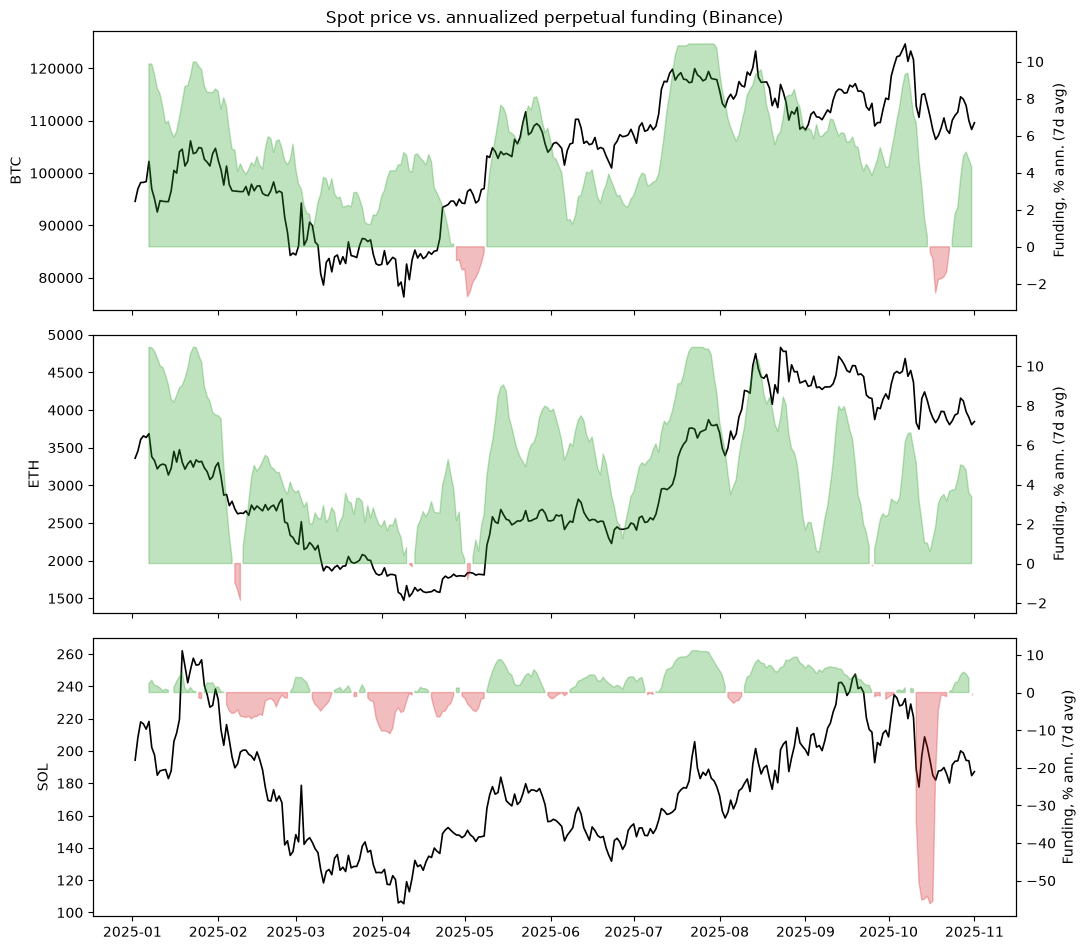

In [5]:
fig, axes = plt.subplots(len(COINS), 1, figsize=(11, 3.2 * len(COINS)), sharex=True)
for ax, coin in zip(axes, COINS):
    ax.plot(spot.index, spot[coin], color="black", lw=1.2, label="Spot close")
    ax.set_ylabel(coin.replace("USDT", ""))
    ax2 = ax.twinx()
    f = funding_daily_ann[coin].rolling(7).mean()
    ax2.fill_between(f.index, 0, f, where=f >= 0, color="tab:green", alpha=0.3)
    ax2.fill_between(f.index, 0, f, where=f < 0, color="tab:red", alpha=0.3)
    ax2.set_ylabel("Funding, % ann. (7d avg)")
axes[0].set_title("Spot price vs. annualized perpetual funding (Binance)")
plt.tight_layout()

## 4. What did the carry trade earn?

Long spot and short perp is roughly delta-neutral. It collects the funding paid (before fees, slippage and basis moves).

In [6]:
carry = funding.sum() * 100
days = (funding.index.max() - funding.index.min()).days
summary = pd.DataFrame({
    "cumulative funding %": carry.round(2),
    "annualized %": (carry * 365 / days).round(2),
    "% of periods positive": (funding.gt(0).mean() * 100).round(1),
})
summary

,cumulative funding %,annualized %,% of periods positive
BTCUSDT,4.24,5.10,86.8
ETHUSDT,4.14,4.99,83.2
SOLUSDT,0.17,0.21,60.9


## Takeaways

- Funding is a **crowding gauge**. Spikes tend to cluster near local price tops, when leveraged longs pay up.
- Carry is **not free**. Negative-funding stretches and exchange risk eat into it.
- Want z-scored crowding signals (funding, basis, open interest, long/short) already built? See the `crypto_leverage` dataset in [Nemeton Signals](https://aurastream.unbiased-alpha.com/docs/data-sources/signals/).

---
### Next steps

- **Get a free key**: 500 calls a month across all 47 sources, no card: [aurastream.unbiased-alpha.com](https://aurastream.unbiased-alpha.com)
- **Docs**: [aurastream.unbiased-alpha.com/docs](https://aurastream.unbiased-alpha.com/docs/)
- **Use it from Claude or ChatGPT**: `pip install aurastream-mcp`
- Found this useful? ⭐ the repo: [github.com/UnbiasedAlpha/aurastream-python](https://github.com/UnbiasedAlpha/aurastream-python)

*Built by [Unbiased Alpha](https://unbiased-alpha.com). For research and education only; not investment advice.*